In [1]:
import sys

print(sys.executable)
print(sys.version)

/Users/ankanpandey/landslide-detection/venv/bin/python
3.12.14 (main, Aug 12 2026, 13:57:54) [Clang 17.0.0 (clang-1700.6.4.2)]


In [2]:
import numpy as np
import pandas as pd

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.5.2
Pandas: 3.0.5


In [3]:
import rasterio

print("Rasterio:", rasterio.__version__)

Rasterio: 1.5.1


In [4]:
import sklearn

print("Scikit-learn:", sklearn.__version__)

Scikit-learn: 1.9.0


In [5]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


# Machine Learning and Deep Learning Based Landslide Detection

## Project Objective

This project aims to identify landslide-affected areas from satellite imagery using Machine Learning and Deep Learning techniques.

### Study Components

- Sentinel-2 satellite imagery
- Spectral feature extraction
- NDVI and NDWI
- Random Forest classification
- Lightweight CNN
- Accuracy, Precision, Recall, F1-score and IoU
- Landslide mapping
- Affected-area estimation

In [6]:
import sys
print(sys.executable)
print(sys.version)

/Users/ankanpandey/landslide-detection/venv/bin/python
3.12.14 (main, Aug 12 2026, 13:57:54) [Clang 17.0.0 (clang-1700.6.4.2)]


In [7]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [8]:
with h5py.File(image_path, "r") as f:
    print("Image keys:", list(f.keys()))

NameError: name 'image_path' is not defined

In [9]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

image_path = "../data/Landslide4Sense/images/train/image_1.h5"
mask_path = "../data/Landslide4Sense/annotations/train/mask_1.h5"

print("Image path:", image_path)
print("Mask path:", mask_path)

Image path: ../data/Landslide4Sense/images/train/image_1.h5
Mask path: ../data/Landslide4Sense/annotations/train/mask_1.h5


In [10]:
import os

print("Image exists:", os.path.exists(image_path))
print("Mask exists:", os.path.exists(mask_path))

Image exists: True
Mask exists: True


In [2]:
with h5py.File(image_path, "r") as f:
    print("Image keys:", list(f.keys()))

NameError: name 'h5py' is not defined

In [3]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

image_path = "../data/Landslide4Sense/images/train/image_1.h5"
mask_path = "../data/Landslide4Sense/annotations/train/mask_1.h5"

print("Image path:", image_path)
print("Mask path:", mask_path)

Image path: ../data/Landslide4Sense/images/train/image_1.h5
Mask path: ../data/Landslide4Sense/annotations/train/mask_1.h5


In [4]:
import os

print("Image exists:", os.path.exists(image_path))
print("Mask exists:", os.path.exists(mask_path))

Image exists: True
Mask exists: True


In [5]:
with h5py.File(image_path, "r") as f:
    print("Image keys:", list(f.keys()))

Image keys: ['img']


In [6]:
with h5py.File(mask_path, "r") as f:
    print("Mask keys:", list(f.keys()))

Mask keys: ['mask']


In [7]:
with h5py.File(image_path, "r") as f:
    image = f["img"][:]

print("Image shape:", image.shape)
print("Image data type:", image.dtype)
print("Image minimum:", np.min(image))
print("Image maximum:", np.max(image))

Image shape: (128, 128, 14)
Image data type: float64
Image minimum: 0.0
Image maximum: 6.397335147428777


In [8]:
with h5py.File(mask_path, "r") as f:
    mask = f["mask"][:]

print("Mask shape:", mask.shape)
print("Mask data type:", mask.dtype)
print("Unique mask values:", np.unique(mask))

Mask shape: (128, 128)
Mask data type: uint8
Unique mask values: [0 1]


In [9]:
print("Number of bands:", image.shape[2])

for i in range(image.shape[2]):
    band = image[:, :, i]
    print(
        f"Band {i}: "
        f"min={band.min():.4f}, "
        f"max={band.max():.4f}, "
        f"mean={band.mean():.4f}"
    )

Number of bands: 14
Band 0: min=1.0955, max=1.6783, mean=1.1678
Band 1: min=1.0744, max=2.7382, mean=1.2258
Band 2: min=0.9979, max=3.5393, mean=1.3379
Band 3: min=0.9861, max=4.8296, mean=1.4699
Band 4: min=0.8810, max=3.3630, mean=1.5095
Band 5: min=0.6887, max=2.2614, mean=1.2940
Band 6: min=0.6590, max=2.1689, mean=1.2606
Band 7: min=0.5491, max=2.2711, mean=1.2533
Band 8: min=0.8471, max=1.7416, mean=1.2382
Band 9: min=1.2158, max=1.7684, mean=1.4871
Band 10: min=0.6535, max=3.3169, mean=1.5542
Band 11: min=0.6155, max=6.3973, mean=1.7011
Band 12: min=0.0000, max=3.6960, mean=1.4253
Band 13: min=0.8113, max=1.7106, mean=1.2556


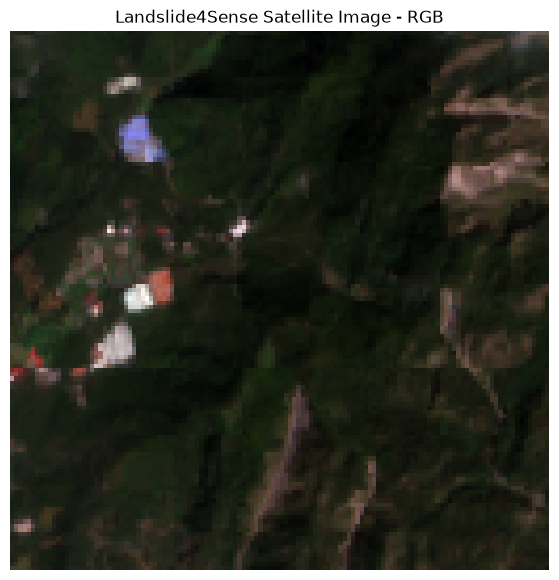

In [10]:
# Extract RGB bands
blue = image[:, :, 1]
green = image[:, :, 2]
red = image[:, :, 3]

# Create RGB image
rgb = np.stack([red, green, blue], axis=-1)

# Normalize each channel for visualization
rgb_min = rgb.min(axis=(0, 1), keepdims=True)
rgb_max = rgb.max(axis=(0, 1), keepdims=True)

rgb_normalized = (rgb - rgb_min) / (rgb_max - rgb_min + 1e-8)

# Display
plt.figure(figsize=(7, 7))
plt.imshow(rgb_normalized)
plt.title("Landslide4Sense Satellite Image - RGB")
plt.axis("off")
plt.show()

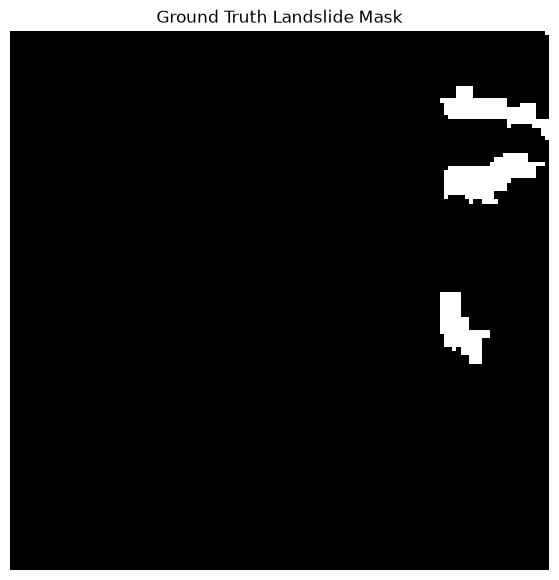

In [11]:
plt.figure(figsize=(7, 7))
plt.imshow(mask, cmap="gray")
plt.title("Ground Truth Landslide Mask")
plt.axis("off")
plt.show()

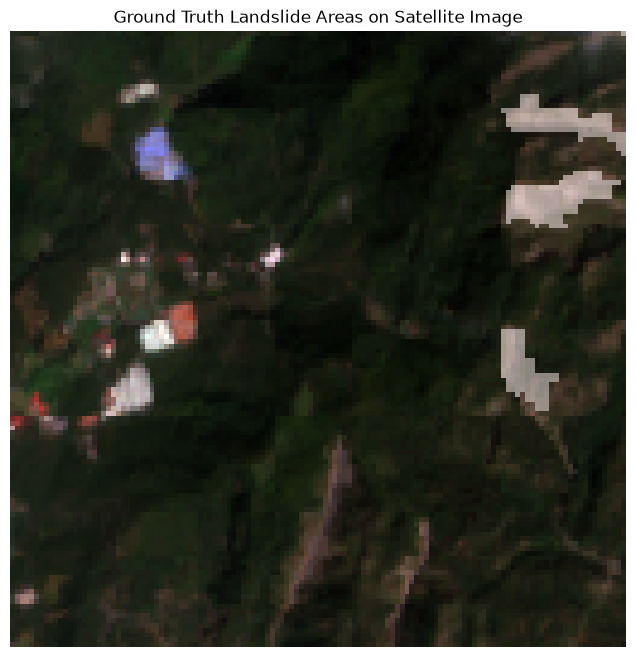

In [12]:
plt.figure(figsize=(8, 8))

plt.imshow(rgb_normalized)

# Overlay landslide pixels
plt.imshow(
    np.ma.masked_where(mask == 0, mask),
    cmap="Reds",
    alpha=0.5
)

plt.title("Ground Truth Landslide Areas on Satellite Image")
plt.axis("off")
plt.show()

In [13]:
# Extract required bands
blue = image[:, :, 1]
green = image[:, :, 2]
red = image[:, :, 3]
nir = image[:, :, 7]

# Calculate NDVI
ndvi = (nir - red) / (nir + red + 1e-8)

# Calculate NDWI
ndwi = (green - nir) / (green + nir + 1e-8)

print("NDVI shape:", ndvi.shape)
print("NDVI min:", np.min(ndvi))
print("NDVI max:", np.max(ndvi))
print("NDVI mean:", np.mean(ndvi))

print("\nNDWI shape:", ndwi.shape)
print("NDWI min:", np.min(ndwi))
print("NDWI max:", np.max(ndwi))
print("NDWI mean:", np.mean(ndwi))

NDVI shape: (128, 128)
NDVI min: -0.5472034549658709
NDVI max: 0.22845440579127327
NDVI mean: -0.0726938713484245

NDWI shape: (128, 128)
NDWI min: -0.18745525634986002
NDWI max: 0.4392135535556599
NDWI mean: 0.035492441402436944


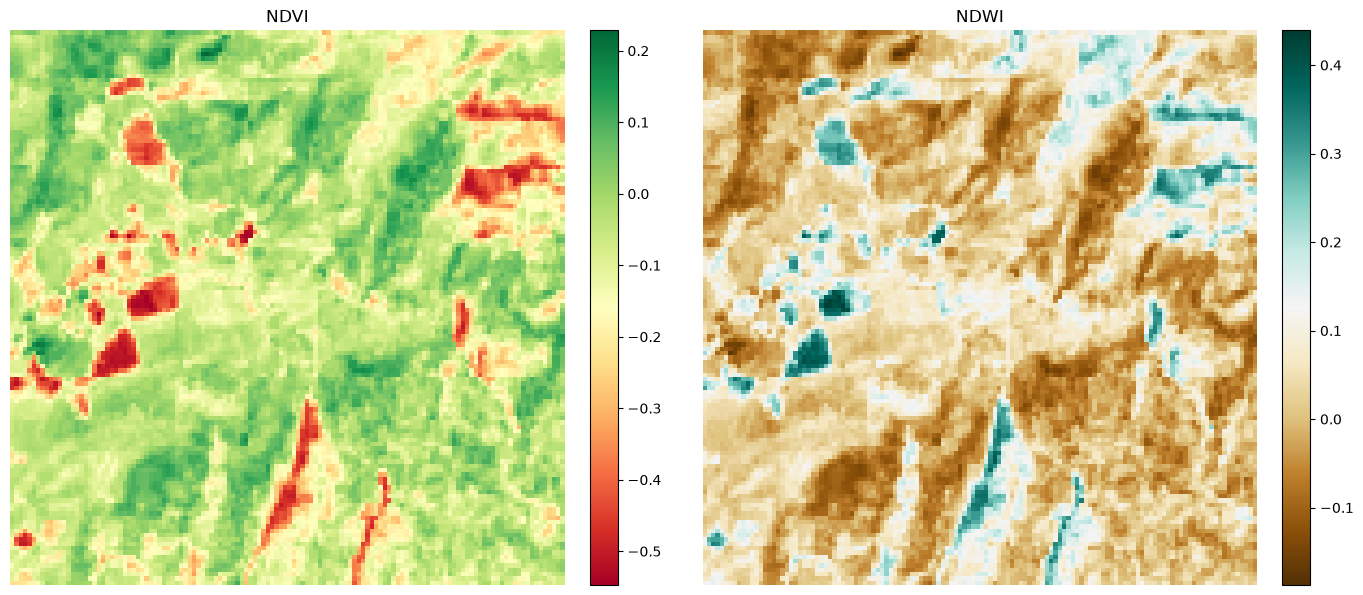

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

im1 = axes[0].imshow(ndvi, cmap="RdYlGn")
axes[0].set_title("NDVI")
axes[0].axis("off")
plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)

im2 = axes[1].imshow(ndwi, cmap="BrBG")
axes[1].set_title("NDWI")
axes[1].axis("off")
plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

In [15]:
# Create pixel-level feature matrix

features = np.stack(
    [
        blue,
        green,
        red,
        nir,
        ndvi,
        ndwi
    ],
    axis=-1
)

# Flatten spatial dimensions
X = features.reshape(-1, 6)

# Flatten mask
y = mask.reshape(-1)

print("Feature image shape:", features.shape)
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nFirst pixel features:")
print(X[0])

print("\nFirst pixel label:")
print(y[0])

Feature image shape: (128, 128, 6)
Feature matrix shape: (16384, 6)
Target shape: (16384,)

First pixel features:
[ 1.26844503  1.40032723  1.53198904  1.55873139  0.00865246 -0.05353194]

First pixel label:
0


In [16]:
class_weight="balanced"

In [17]:
# Check feature matrix
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

# Check class distribution
unique, counts = np.unique(y, return_counts=True)

print("\nClass distribution:")
for label, count in zip(unique, counts):
    percentage = (count / len(y)) * 100
    print(f"Class {label}: {count} pixels ({percentage:.2f}%)")

Feature matrix shape: (16384, 6)
Target shape: (16384,)

Class distribution:
Class 0: 15979 pixels (97.53%)
Class 1: 405 pixels (2.47%)


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Training features:", X_train.shape[1])

Training samples: 13107
Testing samples: 3277
Training features: 6


In [19]:
# Check feature matrix
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

# Check class distribution
unique, counts = np.unique(y, return_counts=True)

print("\nClass distribution:")
for label, count in zip(unique, counts):
    percentage = (count / len(y)) * 100
    class_name = "Non-landslide" if label == 0 else "Landslide"
    print(f"{class_name} ({label}): {count} pixels ({percentage:.2f}%)")

Feature matrix shape: (16384, 6)
Target shape: (16384,)

Class distribution:
Non-landslide (0): 15979 pixels (97.53%)
Landslide (1): 405 pixels (2.47%)


In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])

Training samples: 13107
Testing samples: 3277
Number of features: 6


In [21]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [22]:
y_pred = rf_model.predict(X_test)

print("Predictions generated!")
print("Prediction shape:", y_pred.shape)

Predictions generated!
Prediction shape: (3277,)


In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Random Forest Results")
print("---------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Random Forest Results
---------------------
Accuracy : 0.9768
Precision: 0.5294
Recall   : 0.5556
F1-score : 0.5422

Confusion Matrix:
[[3156   40]
 [  36   45]]


In [24]:
from sklearn.metrics import jaccard_score

iou = jaccard_score(y_test, y_pred, zero_division=0)

print(f"IoU      : {iou:.4f}")

IoU      : 0.3719


In [25]:
# Predict all pixels in the image
full_prediction = rf_model.predict(X)

# Convert the 1D predictions back to the original image shape
rf_prediction_map = full_prediction.reshape(128, 128)

print("Prediction map shape:", rf_prediction_map.shape)
print("Unique prediction values:", np.unique(rf_prediction_map))

Prediction map shape: (128, 128)
Unique prediction values: [0 1]


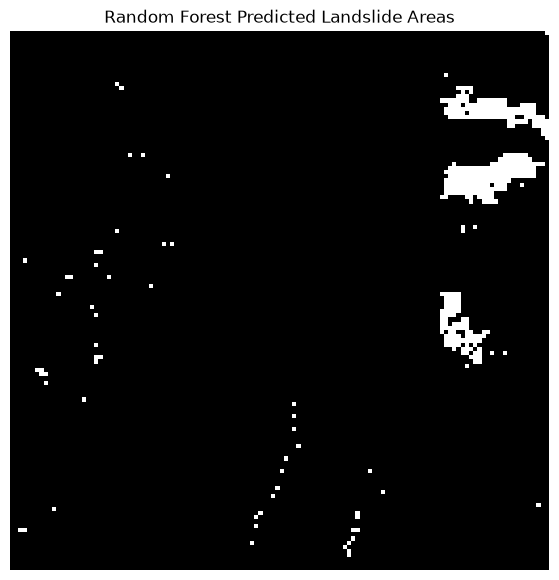

In [26]:
plt.figure(figsize=(7, 7))

plt.imshow(rf_prediction_map, cmap="gray")

plt.title("Random Forest Predicted Landslide Areas")
plt.axis("off")
plt.show()

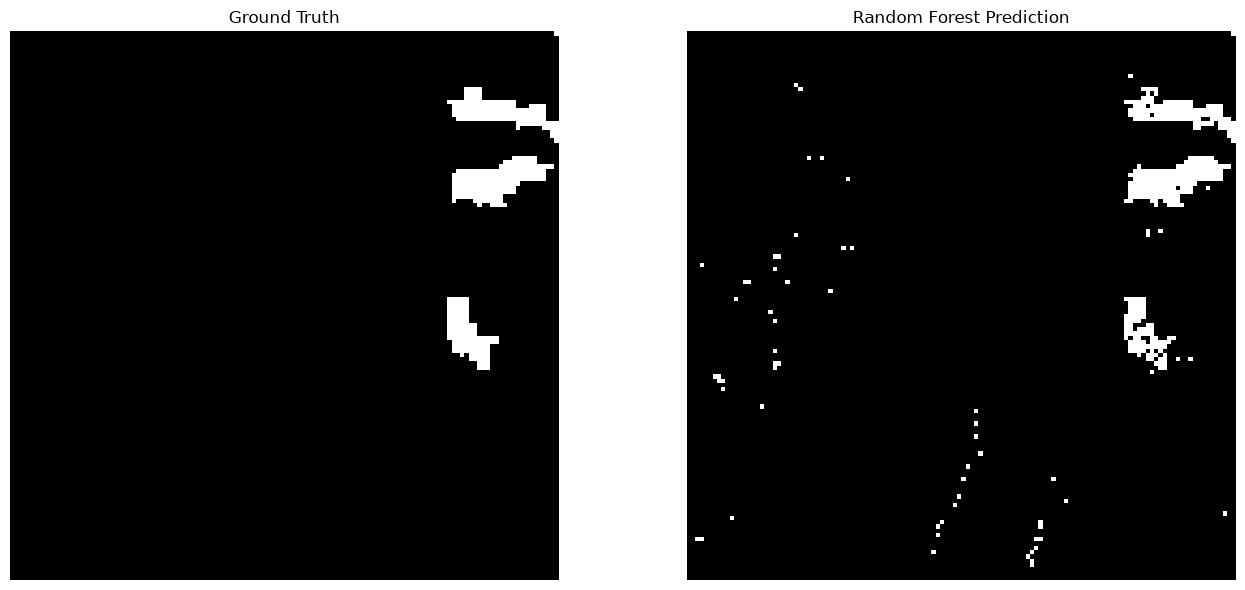

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Ground truth
axes[0].imshow(mask, cmap="gray")
axes[0].set_title("Ground Truth")
axes[0].axis("off")

# Random Forest prediction
axes[1].imshow(rf_prediction_map, cmap="gray")
axes[1].set_title("Random Forest Prediction")
axes[1].axis("off")

plt.tight_layout()
plt.show()

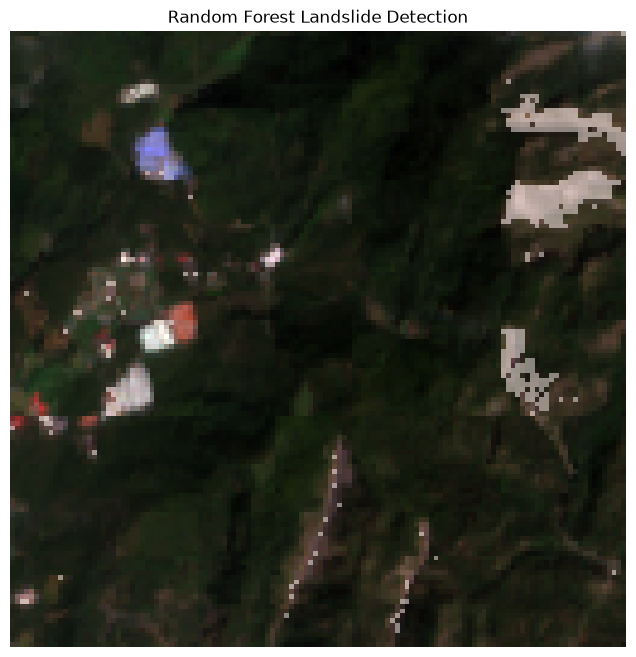

In [28]:
plt.figure(figsize=(8, 8))

# Satellite image
plt.imshow(rgb_normalized)

# Predicted landslide regions
plt.imshow(
    np.ma.masked_where(rf_prediction_map == 0, rf_prediction_map),
    cmap="Reds",
    alpha=0.5
)

plt.title("Random Forest Landslide Detection")
plt.axis("off")
plt.show()

In [29]:
total_pixels = rf_prediction_map.size
predicted_landslide_pixels = np.sum(rf_prediction_map == 1)

predicted_percentage = (
    predicted_landslide_pixels / total_pixels
) * 100

ground_truth_pixels = np.sum(mask == 1)

ground_truth_percentage = (
    ground_truth_pixels / total_pixels
) * 100

print("Total pixels:", total_pixels)
print("Predicted landslide pixels:", predicted_landslide_pixels)
print(f"Predicted landslide coverage: {predicted_percentage:.2f}%")

print("\nGround truth landslide pixels:", ground_truth_pixels)
print(f"Ground truth coverage: {ground_truth_percentage:.2f}%")

Total pixels: 16384
Predicted landslide pixels: 439
Predicted landslide coverage: 2.68%

Ground truth landslide pixels: 405
Ground truth coverage: 2.47%


In [30]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Keras version:", tf.keras.__version__)

TensorFlow version: 2.21.0
Keras version: 3.15.1


In [31]:
# CNN patch configuration
PATCH_SIZE = 16

# Number of complete patches in each dimension
num_patches_h = image.shape[0] // PATCH_SIZE
num_patches_w = image.shape[1] // PATCH_SIZE

print("Patch size:", PATCH_SIZE)
print("Patches vertically:", num_patches_h)
print("Patches horizontally:", num_patches_w)
print("Total patches:", num_patches_h * num_patches_w)

Patch size: 16
Patches vertically: 8
Patches horizontally: 8
Total patches: 64


In [32]:
# Create image patches and corresponding labels

cnn_patches = []
cnn_labels = []

for i in range(num_patches_h):
    for j in range(num_patches_w):

        row_start = i * PATCH_SIZE
        row_end = row_start + PATCH_SIZE

        col_start = j * PATCH_SIZE
        col_end = col_start + PATCH_SIZE

        # Extract 16x16x6 feature patch
        patch = features[
            row_start:row_end,
            col_start:col_end,
            :
        ]

        # Extract corresponding mask patch
        mask_patch = mask[
            row_start:row_end,
            col_start:col_end
        ]

        # Label patch as landslide if it contains landslide pixels
        if np.any(mask_patch == 1):
            label = 1
        else:
            label = 0

        cnn_patches.append(patch)
        cnn_labels.append(label)

cnn_patches = np.array(cnn_patches, dtype=np.float32)
cnn_labels = np.array(cnn_labels, dtype=np.float32)

print("CNN patch shape:", cnn_patches.shape)
print("CNN labels shape:", cnn_labels.shape)

print("\nPatch class distribution:")
print("Non-landslide patches:", np.sum(cnn_labels == 0))
print("Landslide patches:", np.sum(cnn_labels == 1))

CNN patch shape: (64, 16, 16, 6)
CNN labels shape: (64,)

Patch class distribution:
Non-landslide patches: 55
Landslide patches: 9


In [33]:
from sklearn.model_selection import train_test_split

X_cnn_train, X_cnn_test, y_cnn_train, y_cnn_test = train_test_split(
    cnn_patches,
    cnn_labels,
    test_size=0.25,
    random_state=42,
    stratify=cnn_labels
)

print("CNN training patches:", X_cnn_train.shape)
print("CNN testing patches:", X_cnn_test.shape)

print("\nTraining class distribution:")
print("Non-landslide:", np.sum(y_cnn_train == 0))
print("Landslide:", np.sum(y_cnn_train == 1))

print("\nTesting class distribution:")
print("Non-landslide:", np.sum(y_cnn_test == 0))
print("Landslide:", np.sum(y_cnn_test == 1))

CNN training patches: (48, 16, 16, 6)
CNN testing patches: (16, 16, 16, 6)

Training class distribution:
Non-landslide: 41
Landslide: 7

Testing class distribution:
Non-landslide: 14
Landslide: 2


In [34]:
# Calculate mean and standard deviation from training data
cnn_mean = X_cnn_train.mean(axis=(0, 1, 2), keepdims=True)
cnn_std = X_cnn_train.std(axis=(0, 1, 2), keepdims=True)

# Avoid division by zero
cnn_std = np.where(cnn_std < 1e-8, 1.0, cnn_std)

# Normalize training and testing data
X_cnn_train_norm = (X_cnn_train - cnn_mean) / cnn_std
X_cnn_test_norm = (X_cnn_test - cnn_mean) / cnn_std

print("Normalized training shape:", X_cnn_train_norm.shape)
print("Normalized testing shape:", X_cnn_test_norm.shape)

print(
    "Training mean after normalization:",
    X_cnn_train_norm.mean()
)

print(
    "Training standard deviation after normalization:",
    X_cnn_train_norm.std()
)

Normalized training shape: (48, 16, 16, 6)
Normalized testing shape: (16, 16, 16, 6)
Training mean after normalization: -1.1324883e-06
Training standard deviation after normalization: 0.9999999


In [35]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

cnn_model = Sequential([
    Conv2D(
        16,
        (3, 3),
        activation="relu",
        input_shape=(16, 16, 6)
    ),

    MaxPooling2D((2, 2)),

    Conv2D(
        32,
        (3, 3),
        activation="relu"
    ),

    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(32, activation="relu"),

    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

cnn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

/Users/ankanpandey/landslide-detection/venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 16)     │           880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 7, 7, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 5, 5, 32)       │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 2, 2, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,681 (37.82 KB)

 Trainable params: 9,681 (37.82 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_cnn_train)

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_cnn_train
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, class_weights_array)
}

print("Class weights:")
print(class_weights)

Class weights:
{0: 0.5853658536585366, 1: 3.4285714285714284}


In [37]:
history = cnn_model.fit(
    X_cnn_train_norm,
    y_cnn_train,
    validation_data=(X_cnn_test_norm, y_cnn_test),
    epochs=30,
    batch_size=8,
    class_weight=class_weights,
    verbose=1
)

print("CNN training completed!")

Epoch 1/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.2708 - loss: 0.7444 - val_accuracy: 0.3125 - val_loss: 0.7122
Epoch 2/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5000 - loss: 0.5910 - val_accuracy: 0.6875 - val_loss: 0.6315
Epoch 3/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7292 - loss: 0.5763 - val_accuracy: 0.8750 - val_loss: 0.5569
Epoch 4/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7917 - loss: 0.5014 - val_accuracy: 0.8750 - val_loss: 0.4970
Epoch 5/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9167 - loss: 0.4571 - val_accuracy: 0.9375 - val_loss: 0.4686
Epoch 6/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9167 - loss: 0.3984 - val_accuracy: 0.8750 - val_loss: 0.4471
Epoch 7/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8542 - loss: 0.4353 - val_accuracy: 0.8750 - val_loss: 0.4411
Epoch 8/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8958 - loss: 0.3354 - val_accuracy: 0.8750 - val_loss: 0.4078
Epoch 9

In [38]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    jaccard_score,
    confusion_matrix
)

# Get probability predictions
cnn_probabilities = cnn_model.predict(
    X_cnn_test_norm,
    verbose=0
).ravel()

# Convert probabilities to binary predictions
cnn_predictions = (cnn_probabilities >= 0.5).astype(int)

# Calculate metrics
cnn_accuracy = accuracy_score(y_cnn_test, cnn_predictions)
cnn_precision = precision_score(
    y_cnn_test,
    cnn_predictions,
    zero_division=0
)
cnn_recall = recall_score(
    y_cnn_test,
    cnn_predictions,
    zero_division=0
)
cnn_f1 = f1_score(
    y_cnn_test,
    cnn_predictions,
    zero_division=0
)
cnn_iou = jaccard_score(
    y_cnn_test,
    cnn_predictions,
    zero_division=0
)

print("CNN Test Results")
print("----------------")
print(f"Accuracy : {cnn_accuracy:.4f}")
print(f"Precision: {cnn_precision:.4f}")
print(f"Recall   : {cnn_recall:.4f}")
print(f"F1-score : {cnn_f1:.4f}")
print(f"IoU      : {cnn_iou:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_cnn_test, cnn_predictions))

CNN Test Results
----------------
Accuracy : 0.9375
Precision: 1.0000
Recall   : 0.5000
F1-score : 0.6667
IoU      : 0.5000

Confusion Matrix:
[[14  0]
 [ 1  1]]


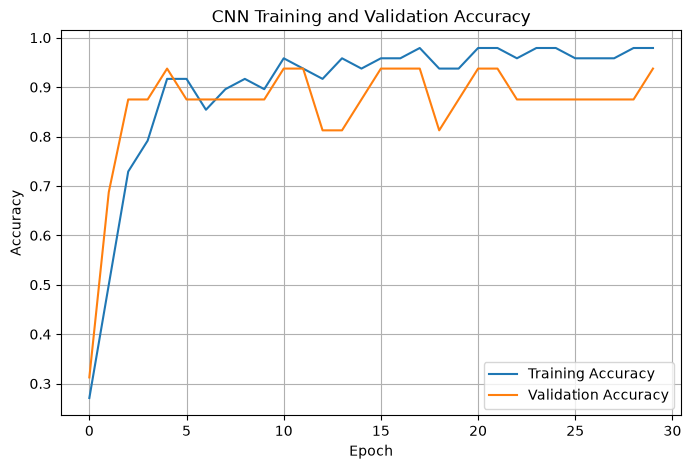

In [39]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

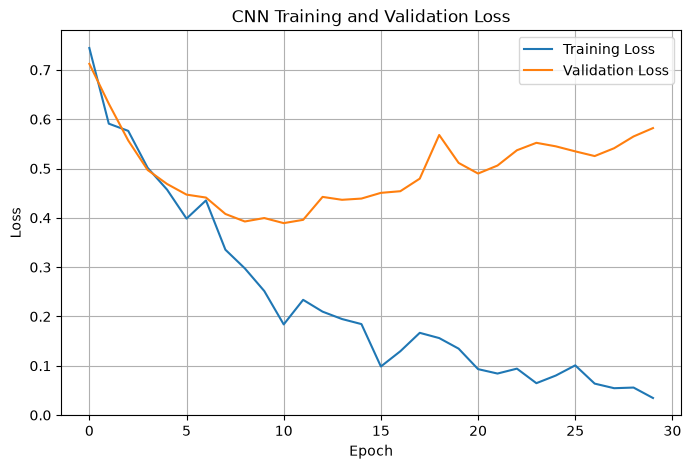

In [40]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

In [41]:
# Normalize all CNN patches using training statistics
cnn_patches_norm = (cnn_patches - cnn_mean) / cnn_std

print("All normalized patches:", cnn_patches_norm.shape)

All normalized patches: (64, 16, 16, 6)


In [42]:
# Predict probability for every patch
all_cnn_probabilities = cnn_model.predict(
    cnn_patches_norm,
    verbose=0
).ravel()

# Convert probabilities to binary labels
all_cnn_predictions = (
    all_cnn_probabilities >= 0.5
).astype(np.uint8)

print("Total patch predictions:", len(all_cnn_predictions))
print("Predicted non-landslide patches:",
      np.sum(all_cnn_predictions == 0))
print("Predicted landslide patches:",
      np.sum(all_cnn_predictions == 1))

Total patch predictions: 64
Predicted non-landslide patches: 55
Predicted landslide patches: 9


In [43]:
# Create empty 128x128 CNN prediction map
cnn_prediction_map = np.zeros(
    (128, 128),
    dtype=np.uint8
)

patch_index = 0

for i in range(num_patches_h):
    for j in range(num_patches_w):

        row_start = i * PATCH_SIZE
        row_end = row_start + PATCH_SIZE

        col_start = j * PATCH_SIZE
        col_end = col_start + PATCH_SIZE

        # Fill the complete patch with its prediction
        cnn_prediction_map[
            row_start:row_end,
            col_start:col_end
        ] = all_cnn_predictions[patch_index]

        patch_index += 1

print("CNN prediction map shape:", cnn_prediction_map.shape)
print("Unique values:", np.unique(cnn_prediction_map))

CNN prediction map shape: (128, 128)
Unique values: [0 1]


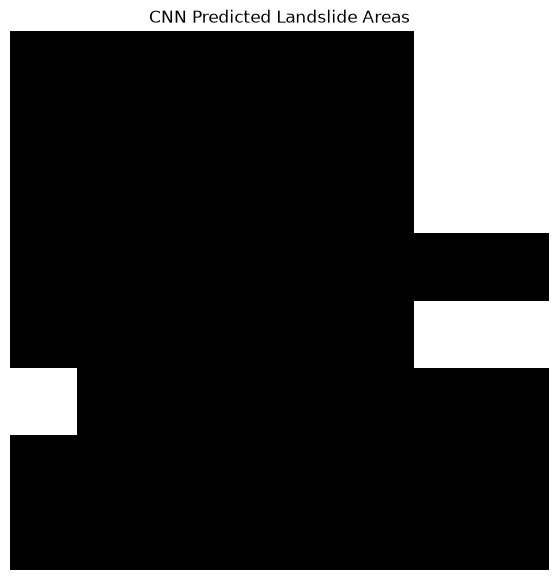

In [44]:
plt.figure(figsize=(7, 7))

plt.imshow(cnn_prediction_map, cmap="gray")

plt.title("CNN Predicted Landslide Areas")
plt.axis("off")

plt.show()

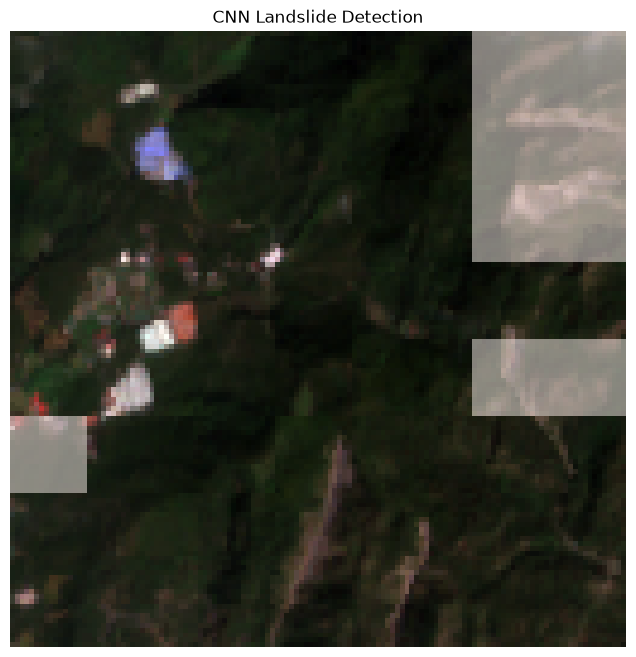

In [45]:
plt.figure(figsize=(8, 8))

plt.imshow(rgb_normalized)

plt.imshow(
    np.ma.masked_where(
        cnn_prediction_map == 0,
        cnn_prediction_map
    ),
    cmap="Reds",
    alpha=0.5
)

plt.title("CNN Landslide Detection")
plt.axis("off")

plt.show()

In [46]:
cnn_total_pixels = cnn_prediction_map.size

cnn_landslide_pixels = np.sum(
    cnn_prediction_map == 1
)

cnn_percentage = (
    cnn_landslide_pixels / cnn_total_pixels
) * 100

print("Total pixels:", cnn_total_pixels)
print("CNN predicted landslide pixels:", cnn_landslide_pixels)
print(f"CNN predicted coverage: {cnn_percentage:.2f}%")

print("\nGround truth coverage: "
      f"{ground_truth_percentage:.2f}%")

print("Random Forest coverage: "
      f"{predicted_percentage:.2f}%")

Total pixels: 16384
CNN predicted landslide pixels: 2304
CNN predicted coverage: 14.06%

Ground truth coverage: 2.47%
Random Forest coverage: 2.68%


In [47]:
# Create 16x16 ground-truth mask patches

cnn_mask_patches = []

for i in range(num_patches_h):
    for j in range(num_patches_w):

        row_start = i * PATCH_SIZE
        row_end = row_start + PATCH_SIZE

        col_start = j * PATCH_SIZE
        col_end = col_start + PATCH_SIZE

        mask_patch = mask[
            row_start:row_end,
            col_start:col_end
        ]

        cnn_mask_patches.append(mask_patch)

cnn_mask_patches = np.array(
    cnn_mask_patches,
    dtype=np.float32
)

# Add channel dimension
cnn_mask_patches = cnn_mask_patches[..., np.newaxis]

print("CNN input patches:", cnn_patches.shape)
print("CNN mask patches:", cnn_mask_patches.shape)

CNN input patches: (64, 16, 16, 6)
CNN mask patches: (64, 16, 16, 1)


In [48]:
from sklearn.model_selection import train_test_split

indices = np.arange(len(cnn_patches))

train_indices, test_indices = train_test_split(
    indices,
    test_size=0.25,
    random_state=42,
    stratify=cnn_labels
)

X_seg_train = cnn_patches[train_indices]
X_seg_test = cnn_patches[test_indices]

y_seg_train = cnn_mask_patches[train_indices]
y_seg_test = cnn_mask_patches[test_indices]

print("Training images:", X_seg_train.shape)
print("Training masks:", y_seg_train.shape)

print("Testing images:", X_seg_test.shape)
print("Testing masks:", y_seg_test.shape)

Training images: (48, 16, 16, 6)
Training masks: (48, 16, 16, 1)
Testing images: (16, 16, 16, 6)
Testing masks: (16, 16, 16, 1)


In [49]:
seg_mean = X_seg_train.mean(
    axis=(0, 1, 2),
    keepdims=True
)

seg_std = X_seg_train.std(
    axis=(0, 1, 2),
    keepdims=True
)

seg_std = np.where(
    seg_std < 1e-8,
    1.0,
    seg_std
)

X_seg_train_norm = (
    X_seg_train - seg_mean
) / seg_std

X_seg_test_norm = (
    X_seg_test - seg_mean
) / seg_std

print("Training mean:", X_seg_train_norm.mean())
print("Training std:", X_seg_train_norm.std())

Training mean: -1.1324883e-06
Training std: 0.9999999


In [50]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D

seg_model = Sequential([
    Conv2D(
        16,
        (3, 3),
        activation="relu",
        padding="same",
        input_shape=(16, 16, 6)
    ),

    Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    Conv2D(
        16,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    Conv2D(
        1,
        (1, 1),
        activation="sigmoid",
        padding="same"
    )
])

seg_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

seg_model.summary()


/Users/ankanpandey/landslide-detection/venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 16)     │           880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 1)      │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,161 (39.69 KB)

 Trainable params: 10,161 (39.69 KB)

 Non-trainable params: 0 (0.00 B)

In [51]:
# Check pixel-level class distribution in the training masks

train_mask_pixels = y_seg_train.flatten()

unique_pixels, pixel_counts = np.unique(
    train_mask_pixels,
    return_counts=True
)

print("Pixel-level class distribution:")

for label, count in zip(unique_pixels, pixel_counts):
    percentage = (count / len(train_mask_pixels)) * 100

    if label == 0:
        class_name = "Non-landslide"
    else:
        class_name = "Landslide"

    print(
        f"{class_name} ({int(label)}): "
        f"{count} pixels ({percentage:.2f}%)"
    )

Pixel-level class distribution:
Non-landslide (0): 11995 pixels (97.62%)
Landslide (1): 293 pixels (2.38%)


In [52]:
# Calculate positive-class weight

negative_pixels = np.sum(train_mask_pixels == 0)
positive_pixels = np.sum(train_mask_pixels == 1)

pos_weight = negative_pixels / positive_pixels

print("Negative pixels:", negative_pixels)
print("Positive pixels:", positive_pixels)
print(f"Positive class weight: {pos_weight:.2f}")

Negative pixels: 11995
Positive pixels: 293
Positive class weight: 40.94


In [53]:
Negative pixels: 11995
Positive pixels: 293
Positive class weight: 40.94

SyntaxError: invalid syntax (624074388.py, line 1)

In [54]:
import tensorflow as tf

def weighted_binary_crossentropy(y_true, y_pred):
    # Prevent log(0)
    epsilon = tf.keras.backend.epsilon()

    y_pred = tf.clip_by_value(
        y_pred,
        epsilon,
        1.0 - epsilon
    )

    # Binary cross-entropy for each pixel
    loss = -(
        y_true * tf.math.log(y_pred) * pos_weight
        +
        (1.0 - y_true) * tf.math.log(1.0 - y_pred)
    )

    return tf.reduce_mean(loss)

In [55]:
seg_model.compile(
    optimizer="adam",
    loss=weighted_binary_crossentropy,
    metrics=["accuracy"]
)

print("Segmentation CNN compiled with weighted loss!")

Segmentation CNN compiled with weighted loss!


In [56]:
seg_history = seg_model.fit(
    X_seg_train_norm,
    y_seg_train,
    validation_data=(
        X_seg_test_norm,
        y_seg_test
    ),
    epochs=30,
    batch_size=8,
    verbose=1
)

print("Segmentation CNN training completed!")

Epoch 1/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.1667 - loss: 1.1574 - val_accuracy: 0.4463 - val_loss: 1.0188
Epoch 2/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5946 - loss: 1.0058 - val_accuracy: 0.6514 - val_loss: 0.9570
Epoch 3/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7704 - loss: 0.8929 - val_accuracy: 0.7693 - val_loss: 0.8216
Epoch 4/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8406 - loss: 0.7437 - val_accuracy: 0.8235 - val_loss: 0.6962
Epoch 5/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8490 - loss: 0.6136 - val_accuracy: 0.8059 - val_loss: 0.6270
Epoch 6/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8533 - loss: 0.5277 - val_accuracy: 0.8281 - val_loss: 0.5707
Epoch 7/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8727 - loss: 0.4811 - val_accuracy: 0.8611 - val_loss: 0.5514
Epoch 8/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8965 - loss: 0.4595 - val_accuracy: 0.8547 - val_loss: 0.5565
Epoch 9

In [57]:
import tensorflow as tf

def weighted_binary_crossentropy(y_true, y_pred):
    epsilon = tf.keras.backend.epsilon()

    y_pred = tf.clip_by_value(
        y_pred,
        epsilon,
        1.0 - epsilon
    )

    loss = -(
        y_true * tf.math.log(y_pred) * pos_weight
        +
        (1.0 - y_true) * tf.math.log(1.0 - y_pred)
    )

    return tf.reduce_mean(loss)


seg_model.compile(
    optimizer="adam",
    loss=weighted_binary_crossentropy,
    metrics=["accuracy"]
)

print("Segmentation CNN compiled successfully!")

Segmentation CNN compiled successfully!


In [58]:
seg_history = seg_model.fit(
    X_seg_train_norm,
    y_seg_train,
    validation_data=(
        X_seg_test_norm,
        y_seg_test
    ),
    epochs=30,
    batch_size=8,
    verbose=1
)

print("Segmentation CNN training completed!")

Epoch 1/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.9584 - loss: 0.1870 - val_accuracy: 0.9065 - val_loss: 1.0960
Epoch 2/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9472 - loss: 0.1851 - val_accuracy: 0.8867 - val_loss: 1.2190
Epoch 3/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9601 - loss: 0.2699 - val_accuracy: 0.8914 - val_loss: 1.1001
Epoch 4/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9312 - loss: 0.2223 - val_accuracy: 0.8572 - val_loss: 0.8324
Epoch 5/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9257 - loss: 0.2762 - val_accuracy: 0.8884 - val_loss: 0.7480
Epoch 6/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9443 - loss: 0.2618 - val_accuracy: 0.8940 - val_loss: 0.7455
Epoch 7/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9477 - loss: 0.1829 - val_accuracy: 0.8975 - val_loss: 0.8000
Epoch 8/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9581 - loss: 0.1722 - val_accuracy: 0.9131 - val_loss: 0.9372
Epoch 9

In [59]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    jaccard_score,
    confusion_matrix
)

# Predict pixel probabilities
seg_probabilities = seg_model.predict(
    X_seg_test_norm,
    verbose=0
)

# Convert probabilities to binary mask
seg_predictions = (
    seg_probabilities >= 0.5
).astype(np.uint8)

# Flatten predictions and ground truth
y_seg_test_flat = y_seg_test.flatten()
seg_predictions_flat = seg_predictions.flatten()

# Calculate metrics
seg_accuracy = accuracy_score(
    y_seg_test_flat,
    seg_predictions_flat
)

seg_precision = precision_score(
    y_seg_test_flat,
    seg_predictions_flat,
    zero_division=0
)

seg_recall = recall_score(
    y_seg_test_flat,
    seg_predictions_flat,
    zero_division=0
)

seg_f1 = f1_score(
    y_seg_test_flat,
    seg_predictions_flat,
    zero_division=0
)

seg_iou = jaccard_score(
    y_seg_test_flat,
    seg_predictions_flat,
    zero_division=0
)

print("CNN SEGMENTATION TEST RESULTS")
print("=============================")
print(f"Accuracy : {seg_accuracy:.4f}")
print(f"Precision: {seg_precision:.4f}")
print(f"Recall   : {seg_recall:.4f}")
print(f"F1-score : {seg_f1:.4f}")
print(f"IoU      : {seg_iou:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_seg_test_flat,
    seg_predictions_flat
))

CNN SEGMENTATION TEST RESULTS
Accuracy : 0.9263
Precision: 0.1975
Recall   : 0.5536
F1-score : 0.2911
IoU      : 0.1703

Confusion Matrix:
[[3732  252]
 [  50   62]]


In [60]:
# Normalize all 64 patches using training statistics
all_seg_patches_norm = (
    cnn_patches - seg_mean
) / seg_std

print("All normalized patches:",
      all_seg_patches_norm.shape)

All normalized patches: (64, 16, 16, 6)


In [61]:
# Predict pixel probabilities for all patches
all_seg_probabilities = seg_model.predict(
    all_seg_patches_norm,
    verbose=0
)

print("Prediction shape:",
      all_seg_probabilities.shape)

print(
    "Minimum probability:",
    all_seg_probabilities.min()
)

print(
    "Maximum probability:",
    all_seg_probabilities.max()
)

Prediction shape: (64, 16, 16, 1)
Minimum probability: 1.9575124e-34
Maximum probability: 0.99989223


In [62]:
# Convert probabilities into binary predictions
all_seg_predictions = (
    all_seg_probabilities >= 0.5
).astype(np.uint8)

print(
    "Unique prediction values:",
    np.unique(all_seg_predictions)
)

print(
    "Predicted landslide pixels:",
    np.sum(all_seg_predictions == 1)
)

Unique prediction values: [0 1]
Predicted landslide pixels: 857


In [63]:
# Create empty full-size prediction map
cnn_segmentation_map = np.zeros(
    (128, 128),
    dtype=np.uint8
)

patch_index = 0

for i in range(num_patches_h):
    for j in range(num_patches_w):

        row_start = i * PATCH_SIZE
        row_end = row_start + PATCH_SIZE

        col_start = j * PATCH_SIZE
        col_end = col_start + PATCH_SIZE

        cnn_segmentation_map[
            row_start:row_end,
            col_start:col_end
        ] = all_seg_predictions[
            patch_index, :, :, 0
        ]

        patch_index += 1

print(
    "CNN segmentation map shape:",
    cnn_segmentation_map.shape
)

print(
    "Unique values:",
    np.unique(cnn_segmentation_map)
)

CNN segmentation map shape: (128, 128)
Unique values: [0 1]


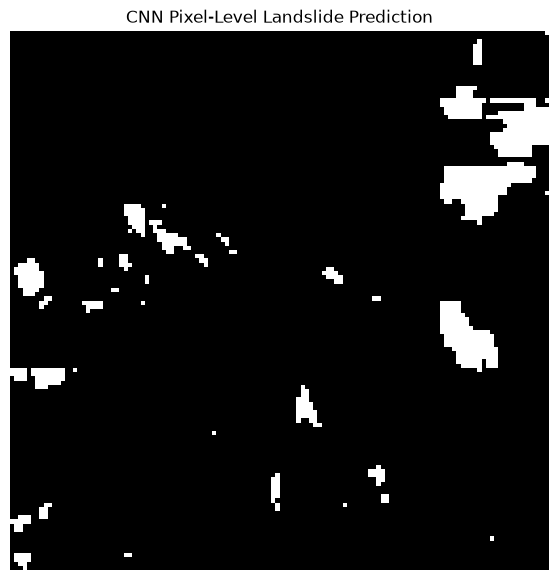

In [64]:
plt.figure(figsize=(7, 7))

plt.imshow(
    cnn_segmentation_map,
    cmap="gray"
)

plt.title("CNN Pixel-Level Landslide Prediction")
plt.axis("off")

plt.show()

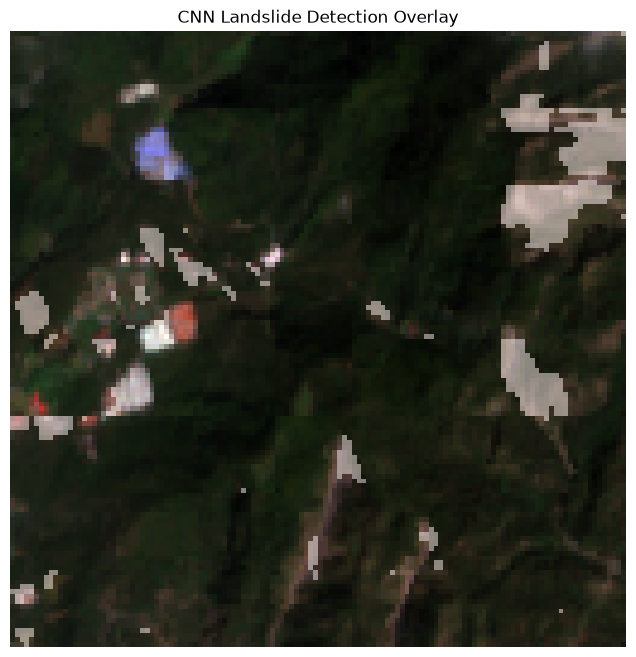

In [65]:
plt.figure(figsize=(8, 8))

plt.imshow(rgb_normalized)

plt.imshow(
    np.ma.masked_where(
        cnn_segmentation_map == 0,
        cnn_segmentation_map
    ),
    cmap="Reds",
    alpha=0.5
)

plt.title("CNN Landslide Detection Overlay")
plt.axis("off")

plt.show()

In [66]:
cnn_seg_pixels = np.sum(
    cnn_segmentation_map == 1
)

cnn_seg_percentage = (
    cnn_seg_pixels /
    cnn_segmentation_map.size
) * 100

print("CNN predicted landslide pixels:",
      cnn_seg_pixels)

print(
    f"CNN predicted landslide coverage: "
    f"{cnn_seg_percentage:.2f}%"
)

print(
    f"Ground truth coverage: "
    f"{ground_truth_percentage:.2f}%"
)

print(
    f"Random Forest coverage: "
    f"{predicted_percentage:.2f}%"
)

CNN predicted landslide pixels: 857
CNN predicted landslide coverage: 5.23%
Ground truth coverage: 2.47%
Random Forest coverage: 2.68%


In [67]:
print("Available RF metric variables:")

for name in [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "iou",
    "rf_accuracy",
    "rf_precision",
    "rf_recall",
    "rf_f1",
    "rf_iou"
]:
    if name in globals():
        print(name, "=", globals()[name])

Available RF metric variables:
accuracy = 0.9768080561489166
precision = 0.5294117647058824
recall = 0.5555555555555556
f1 = 0.5421686746987951
iou = 0.371900826446281


NameError: name 'predicted_mask' is not defined

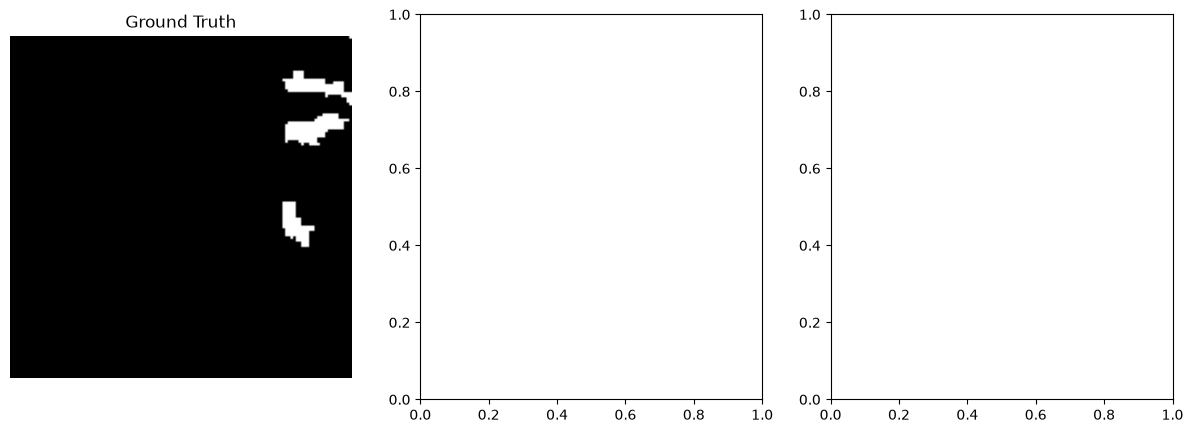

In [68]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5)
)

axes[0].imshow(mask, cmap="gray")
axes[0].set_title("Ground Truth")
axes[0].axis("off")

axes[1].imshow(predicted_mask, cmap="gray")
axes[1].set_title("Random Forest")
axes[1].axis("off")

axes[2].imshow(
    cnn_segmentation_map,
    cmap="gray"
)
axes[2].set_title("CNN Segmentation")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [69]:
print("Variables containing 'mask' or 'pred':")

for name in sorted(globals()):
    if "mask" in name.lower() or "pred" in name.lower():
        obj = globals()[name]

        try:
            print(
                f"{name}: "
                f"shape={obj.shape}, "
                f"dtype={obj.dtype}"
            )
        except:
            print(f"{name}: {type(obj)}")

Variables containing 'mask' or 'pred':
all_cnn_predictions: shape=(64,), dtype=uint8
all_seg_predictions: shape=(64, 16, 16, 1), dtype=uint8
cnn_mask_patches: shape=(64, 16, 16, 1), dtype=float32
cnn_prediction_map: shape=(128, 128), dtype=uint8
cnn_predictions: shape=(16,), dtype=int64
full_prediction: shape=(16384,), dtype=uint8
mask: shape=(128, 128), dtype=uint8
mask_patch: shape=(16, 16), dtype=uint8
mask_path: <class 'str'>
predicted_landslide_pixels: shape=(), dtype=int64
predicted_percentage: shape=(), dtype=float64
rf_prediction_map: shape=(128, 128), dtype=uint8
seg_predictions: shape=(16, 16, 16, 1), dtype=uint8
seg_predictions_flat: shape=(4096,), dtype=uint8
train_mask_pixels: shape=(12288,), dtype=float32
y_pred: shape=(3277,), dtype=uint8


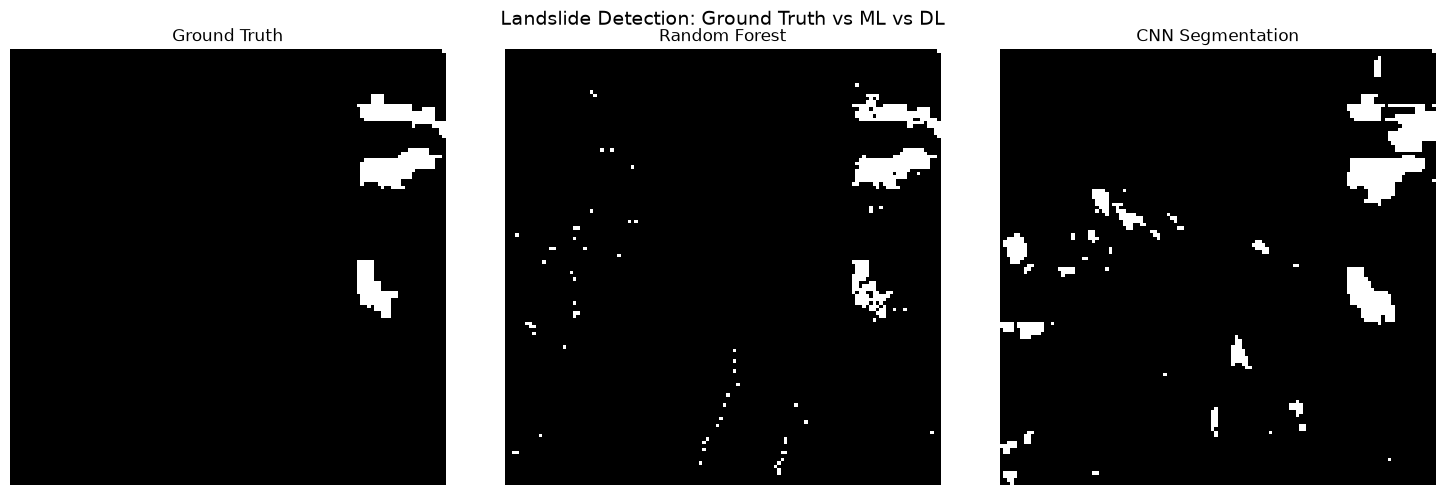

In [70]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5)
)

# Ground truth
axes[0].imshow(mask, cmap="gray")
axes[0].set_title("Ground Truth")
axes[0].axis("off")

# Random Forest
axes[1].imshow(rf_prediction_map, cmap="gray")
axes[1].set_title("Random Forest")
axes[1].axis("off")

# CNN Segmentation
axes[2].imshow(cnn_segmentation_map, cmap="gray")
axes[2].set_title("CNN Segmentation")
axes[2].axis("off")

plt.suptitle(
    "Landslide Detection: Ground Truth vs ML vs DL",
    fontsize=14
)

plt.tight_layout()
plt.show()


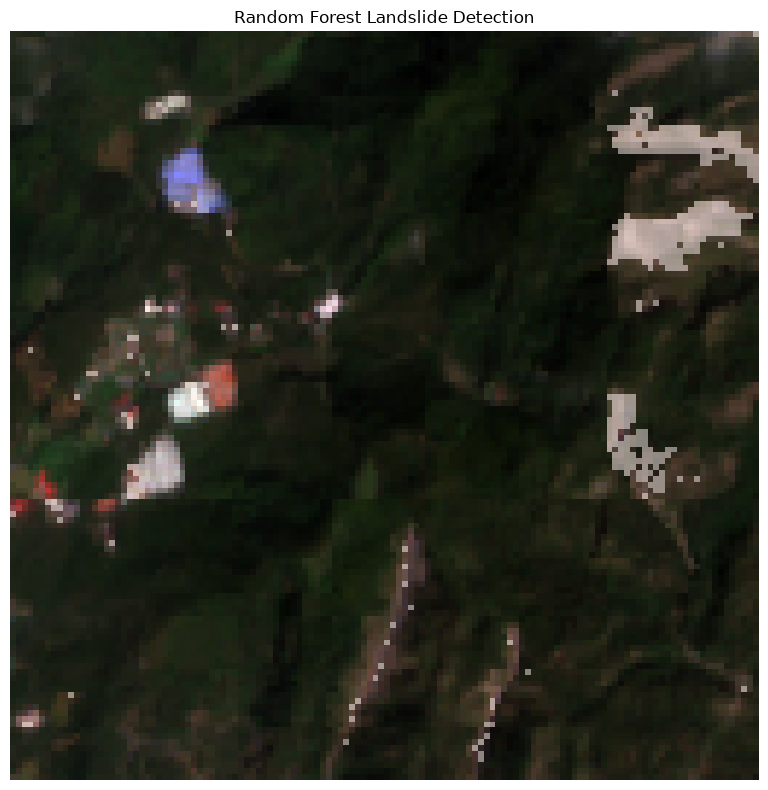

In [71]:
plt.figure(figsize=(8, 8))

plt.imshow(rgb_normalized)

plt.imshow(
    np.ma.masked_where(
        rf_prediction_map == 0,
        rf_prediction_map
    ),
    cmap="Reds",
    alpha=0.5
)

plt.title("Random Forest Landslide Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

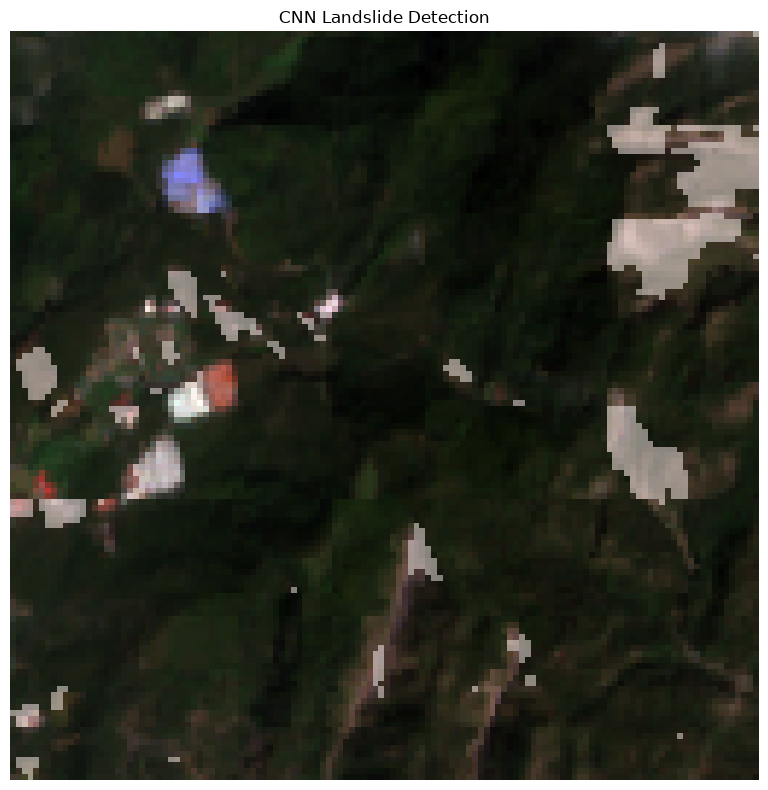

In [72]:
plt.figure(figsize=(8, 8))

plt.imshow(rgb_normalized)

plt.imshow(
    np.ma.masked_where(
        cnn_segmentation_map == 0,
        cnn_segmentation_map
    ),
    cmap="Reds",
    alpha=0.5
)

plt.title("CNN Landslide Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

In [73]:
ground_truth_pixels = np.sum(mask == 1)

rf_pixels = np.sum(
    rf_prediction_map == 1
)

cnn_pixels = np.sum(
    cnn_segmentation_map == 1
)

total_pixels = mask.size

ground_truth_percentage = (
    ground_truth_pixels / total_pixels
) * 100

rf_percentage = (
    rf_pixels / total_pixels
) * 100

cnn_percentage = (
    cnn_pixels / total_pixels
) * 100

print("FINAL COVERAGE COMPARISON")
print("=========================")

print(
    f"Ground Truth: "
    f"{ground_truth_pixels} pixels "
    f"({ground_truth_percentage:.2f}%)"
)

print(
    f"Random Forest: "
    f"{rf_pixels} pixels "
    f"({rf_percentage:.2f}%)"
)

print(
    f"CNN Segmentation: "
    f"{cnn_pixels} pixels "
    f"({cnn_percentage:.2f}%)"
)

FINAL COVERAGE COMPARISON
Ground Truth: 405 pixels (2.47%)
Random Forest: 439 pixels (2.68%)
CNN Segmentation: 857 pixels (5.23%)


In [74]:
rf_coverage_error = (
    abs(rf_pixels - ground_truth_pixels)
    / ground_truth_pixels
) * 100

cnn_coverage_error = (
    abs(cnn_pixels - ground_truth_pixels)
    / ground_truth_pixels
) * 100

print(
    f"Random Forest coverage error: "
    f"{rf_coverage_error:.2f}%"
)

print(
    f"CNN coverage error: "
    f"{cnn_coverage_error:.2f}%"
)

Random Forest coverage error: 8.40%
CNN coverage error: 111.60%


In [75]:
print("Random Forest Metrics")
print("=====================")

for name in [
    "rf_accuracy",
    "rf_precision",
    "rf_recall",
    "rf_f1",
    "rf_iou",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "iou"
]:
    if name in globals():
        print(f"{name}: {globals()[name]}")

Random Forest Metrics
accuracy: 0.9768080561489166
precision: 0.5294117647058824
recall: 0.5555555555555556
f1: 0.5421686746987951
iou: 0.371900826446281


In [76]:
import pandas as pd

comparison_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "IoU"
    ],
    "Random Forest": [
        accuracy,
        precision,
        recall,
        f1,
        iou
    ],
    "CNN Segmentation": [
        seg_accuracy,
        seg_precision,
        seg_recall,
        seg_f1,
        seg_iou
    ]
})

comparison_df

,Metric,Random Forest,CNN Segmentation
0,Accuracy,0.976808,0.926270
1,Precision,0.529412,0.197452
2,Recall,0.555556,0.553571
3,F1-score,0.542169,0.291080
4,IoU,0.371901,0.170330


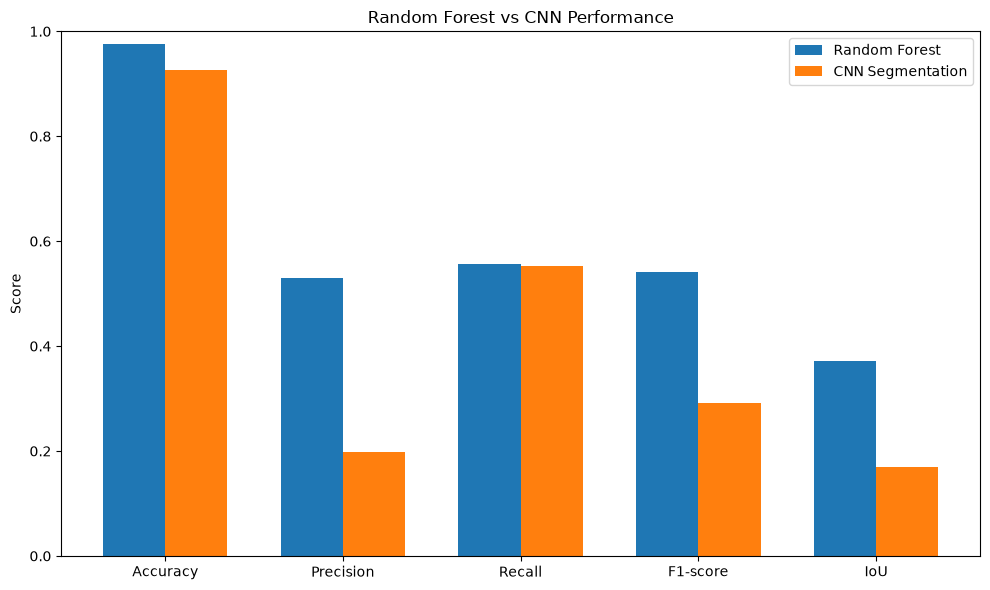

In [77]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "IoU"
]

rf_scores = [
    accuracy,
    precision,
    recall,
    f1,
    iou
]

cnn_scores = [
    seg_accuracy,
    seg_precision,
    seg_recall,
    seg_f1,
    seg_iou
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    rf_scores,
    width,
    label="Random Forest"
)

plt.bar(
    x + width/2,
    cnn_scores,
    width,
    label="CNN Segmentation"
)

plt.xticks(x, metrics)
plt.ylabel("Score")
plt.ylim(0, 1)
plt.title("Random Forest vs CNN Performance")
plt.legend()

plt.tight_layout()
plt.show()

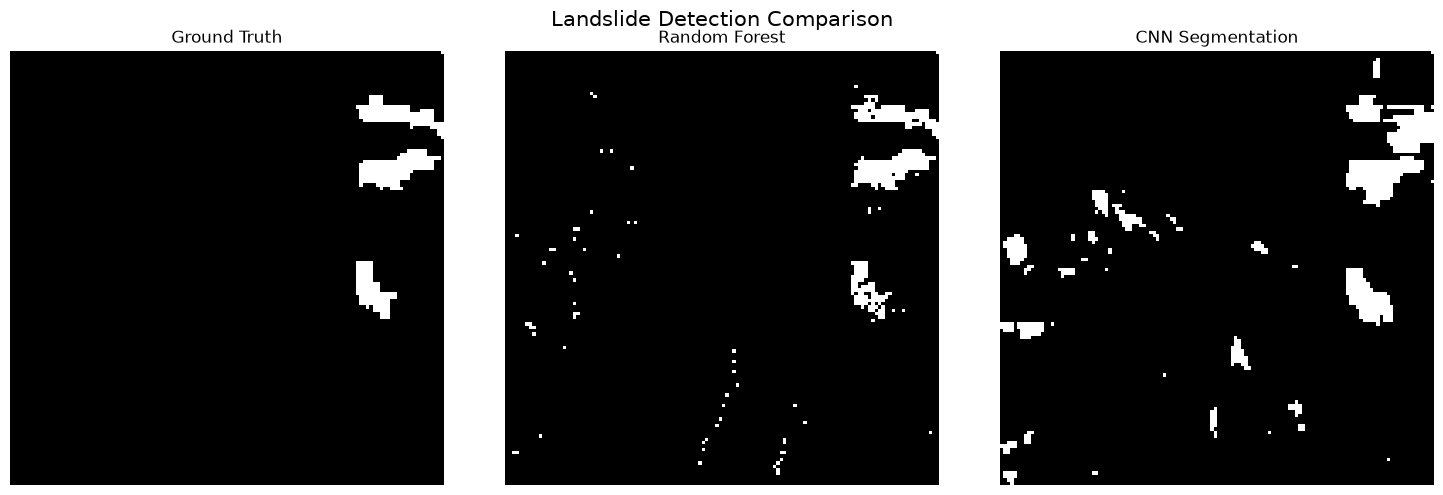

In [78]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)

axes[0].imshow(
    mask,
    cmap="gray"
)

axes[0].set_title(
    "Ground Truth"
)

axes[0].axis("off")


axes[1].imshow(
    rf_prediction_map,
    cmap="gray"
)

axes[1].set_title(
    "Random Forest"
)

axes[1].axis("off")


axes[2].imshow(
    cnn_segmentation_map,
    cmap="gray"
)

axes[2].set_title(
    "CNN Segmentation"
)

axes[2].axis("off")


plt.suptitle(
    "Landslide Detection Comparison",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [79]:
import os

os.makedirs(
    "../outputs/figures",
    exist_ok=True
)

os.makedirs(
    "../outputs/maps",
    exist_ok=True
)

print("Output directories ready!")

Output directories ready!


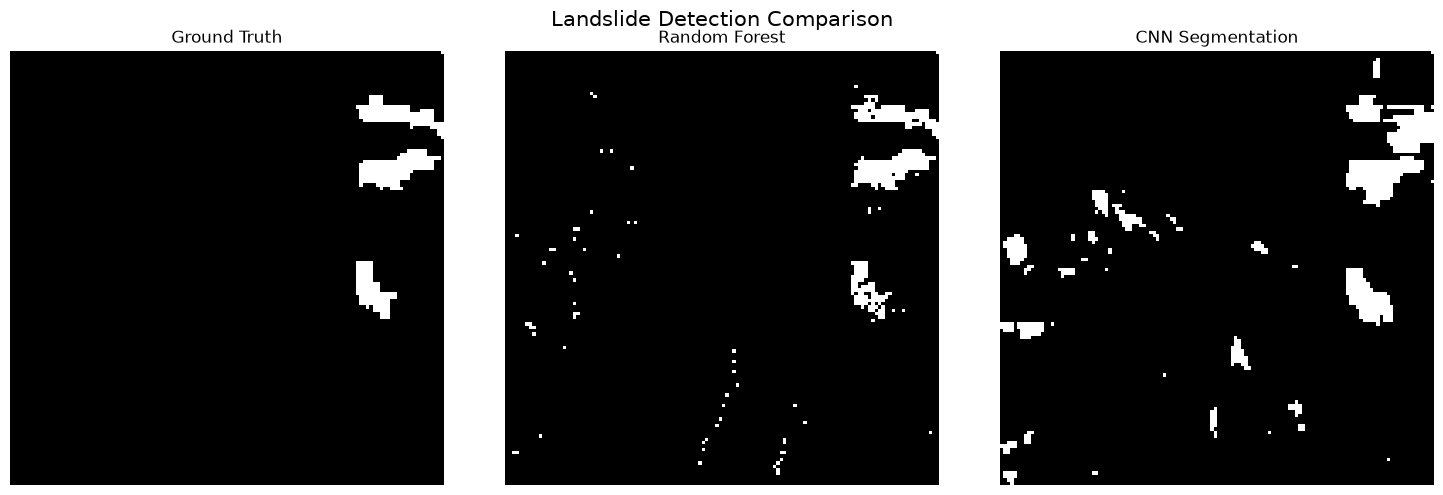

In [80]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)

axes[0].imshow(mask, cmap="gray")
axes[0].set_title("Ground Truth")
axes[0].axis("off")

axes[1].imshow(rf_prediction_map, cmap="gray")
axes[1].set_title("Random Forest")
axes[1].axis("off")

axes[2].imshow(cnn_segmentation_map, cmap="gray")
axes[2].set_title("CNN Segmentation")
axes[2].axis("off")

plt.suptitle(
    "Landslide Detection Comparison",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    "../outputs/figures/landslide_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

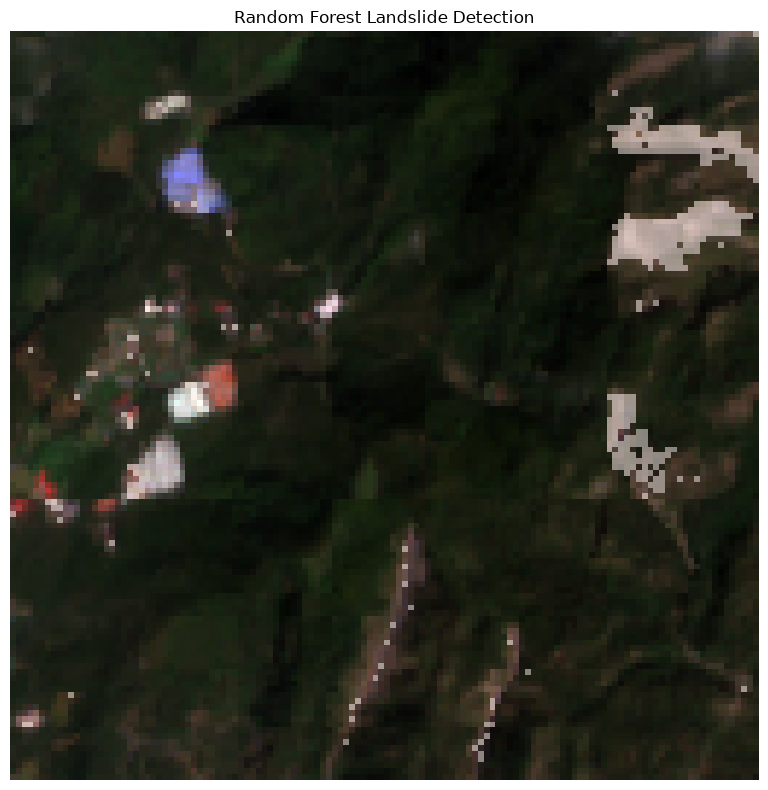

In [81]:
plt.figure(figsize=(8, 8))

plt.imshow(rgb_normalized)

plt.imshow(
    np.ma.masked_where(
        rf_prediction_map == 0,
        rf_prediction_map
    ),
    cmap="Reds",
    alpha=0.5
)

plt.title(
    "Random Forest Landslide Detection"
)

plt.axis("off")

plt.tight_layout()

plt.savefig(
    "../outputs/figures/rf_landslide_overlay.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

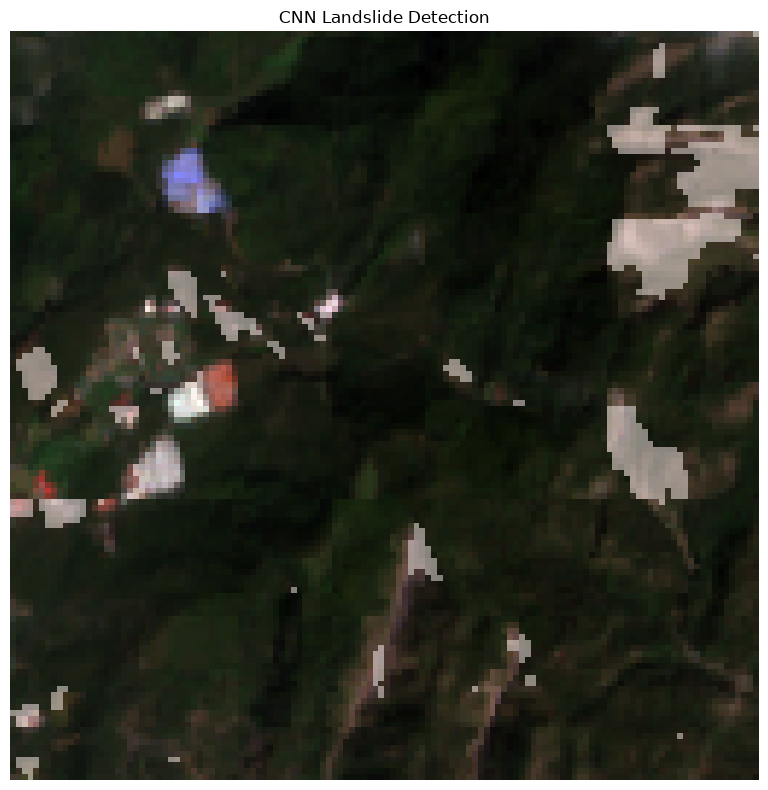

In [82]:
plt.figure(figsize=(8, 8))

plt.imshow(rgb_normalized)

plt.imshow(
    np.ma.masked_where(
        cnn_segmentation_map == 0,
        cnn_segmentation_map
    ),
    cmap="Reds",
    alpha=0.5
)

plt.title(
    "CNN Landslide Detection"
)

plt.axis("off")

plt.tight_layout()

plt.savefig(
    "../outputs/figures/cnn_landslide_overlay.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

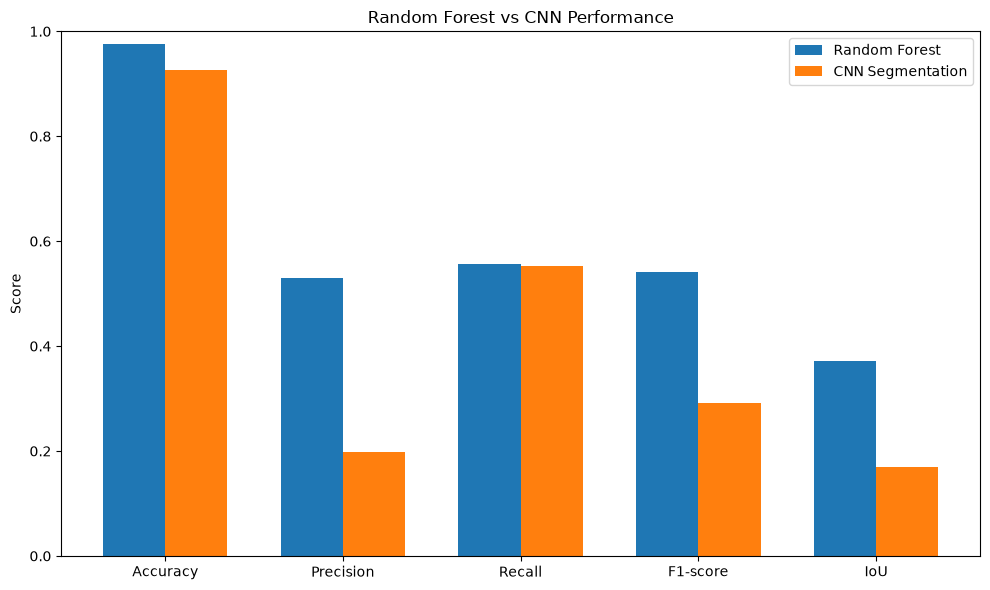

In [83]:
plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    rf_scores,
    width,
    label="Random Forest"
)

plt.bar(
    x + width/2,
    cnn_scores,
    width,
    label="CNN Segmentation"
)

plt.xticks(x, metrics)
plt.ylabel("Score")
plt.ylim(0, 1)

plt.title(
    "Random Forest vs CNN Performance"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "../outputs/figures/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [84]:
seg_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 16)     │           880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 1)      │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,485 (119.09 KB)

 Trainable params: 10,161 (39.69 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 20,324 (79.39 KB)